# Monte Carlo per gli MDP

---

### Gridworld (dall'episodio precedente, vedi lab 6)


Nel Reinforcement Learning (RL), un GridWorld è l'"Hello World" degli ambienti. È uno spazio discreto e bidimensionale in cui un agente si sposta da una cella all'altra per massimizzare le proprie ricompense.

È il ponte perfetto tra teoria e pratica, perché ogni componente di un Processo Decisionale di Markov (MDP) è visibile e numerabile.

Un GridWorld è definito da quattro componenti matematiche fondamentali:

- Stati (S): ogni cella della griglia (ad es. (x,y) oppure un indice appiattito da 0 a 15).

- Azioni (A): di solito quattro mosse discrete: Su, Giù, Sinistra e Destra.

- Transizioni (P): le regole di movimento. In una griglia semplice sono deterministiche (muoversi a 'Destra' porta sempre nella cella a destra). Se si urta un muro, si resta fermi.

- Ricompense (R): il segnale di feedback.

- Penalità per passo: di solito −1 per mossa, per costringere l'agente a trovare il percorso più breve.

- Obiettivo: una grande ricompensa positiva oppure 0 (con penalità altrove).

- Trappole: grandi ricompense negative (ad es. −10) che possono terminare l'episodio.

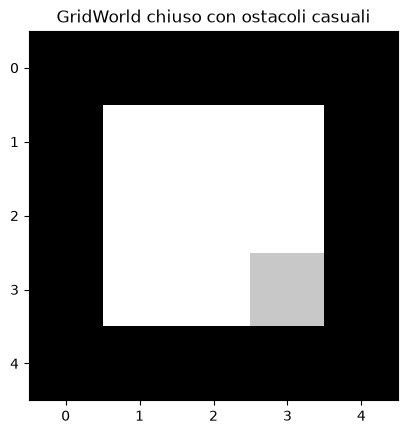

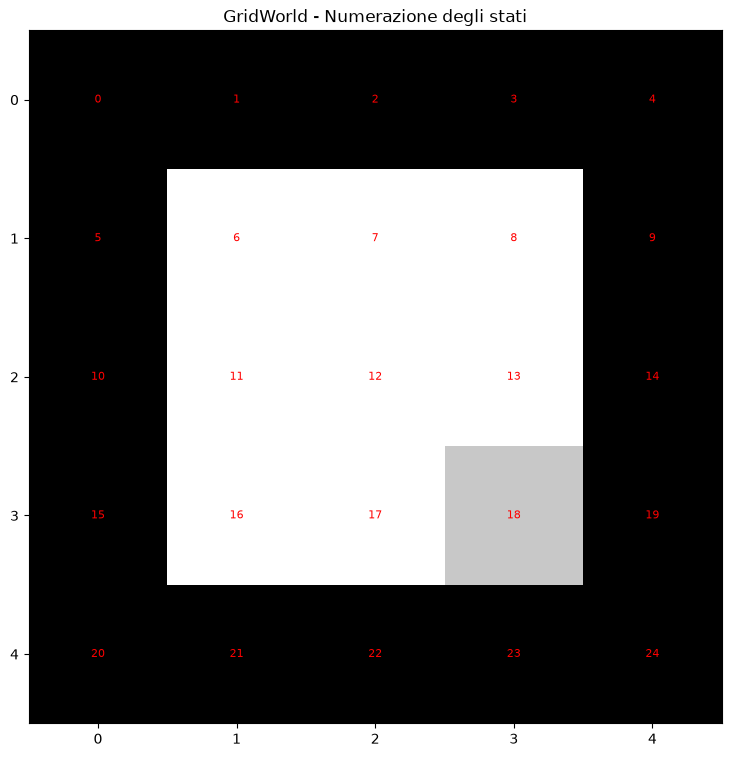

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns

# Codifica dei valori della bitmap:
# 0 = muro, 50 = trappola, 200 = obiettivo, 255 = cella libera


def generate_enclosed_map(rows=30, cols=30, wall_density=0.15, trap_density=0.02):
    """Genero una griglia chiusa da muri, con muri interni e trappole casuali."""
    # 1. Parto da una griglia tutta libera (255)
    grid = np.full((rows, cols), 255, dtype=np.uint8)

    # 2. Metto i muri sul bordo, così l'agente non può uscire
    grid[0, :] = 0   # Muro superiore
    grid[-1, :] = 0  # Muro inferiore
    grid[:, 0] = 0   # Muro sinistro
    grid[:, -1] = 0  # Muro destro

    # 3. Estraggo un numero casuale in [0, 1) per ogni cella interna
    interior_shape = (rows-2, cols-2)
    random_roll = np.random.rand(*interior_shape)

    # 4. Creo una maschera che è True solo all'interno (bordo escluso)
    interior_mask = np.full((rows, cols), False)
    interior_mask[1:-1, 1:-1] = True

    # 5. Le celle con numero < wall_density diventano muri (0),
    #    quelle con numero > 1 - trap_density diventano trappole (50)
    #    (np.pad riporta la matrice interna alla dimensione completa)
    grid[(interior_mask) & (np.pad(random_roll < wall_density, 1, constant_values=False))] = 0
    grid[(interior_mask) & (np.pad(random_roll > 1 - trap_density, 1, constant_values=False))] = 50

    # 6. Metto l'obiettivo nell'ultima cella interna in basso a destra
    grid[-2, -2] = 200    # Obiettivo in basso a destra

    return grid

# 1. Genero una mappa 5x5 e la mostro
rows, cols = 5, 5
grid_bitmap = generate_enclosed_map(rows, cols)
plt.imshow(grid_bitmap, cmap='gray')
plt.title("GridWorld chiuso con ostacoli casuali")

# 2. Rifaccio il grafico più grande, scrivendo in ogni cella il numero dello stato
plt.figure(figsize=(9, 9))
plt.imshow(grid_bitmap, cmap='gray', vmin=0, vmax=255)

rows, cols = grid_bitmap.shape

for r in range(rows):
    for c in range(cols):
        # 3. Indice appiattito dello stato: s = riga * n_colonne + colonna
        state = r * cols + c

        plt.text(
            c, r, str(state),
            ha='center',
            va='center',
            color='red',
            fontsize=8
        )

plt.title("GridWorld - Numerazione degli stati")
plt.xticks(range(cols))
plt.yticks(range(rows))


plt.show()

In [41]:
# Definisco ricompensa ed eventuale terminazione per ogni tipo di cella
WORLD_CONFIG = {
    0:   {"reward": 0,      "terminal": False, "label": "Wall"},   # Penalità gestita dal 'restare fermi'
    50:  {"reward": -10,    "terminal": True,  "label": "Trap"},   # Grande penalità, termina il gioco
    200: {"reward": 10,     "terminal": True,  "label": "Goal"},   # Grande premio, termina il gioco
    255: {"reward": -0.1,     "terminal": False, "label": "Path"}    # Costo per passo per incoraggiare la velocità
}

def parse_grid(grid_bitmap):
    """Converto la bitmap in due mappe: ricompense e stati terminali."""
    rows, cols = grid_bitmap.shape
    # 1. Inizializzo la mappa delle ricompense e la maschera dei terminali
    reward_grid = np.zeros((rows, cols))
    terminal_mask = np.zeros((rows, cols), dtype=bool)

    for val, props in WORLD_CONFIG.items():
        # 2. Trovo tutte le celle della bitmap con questo valore
        mask = (grid_bitmap == val)
        # 3. Assegno a quelle celle la ricompensa e il flag terminale
        reward_grid[mask] = props["reward"]
        terminal_mask[mask] = props["terminal"]

    return reward_grid, terminal_mask

reward_grid, terminal_mask = parse_grid(grid_bitmap)

In [42]:
MOVEMENTS = [(-1, 0), (1, 0), (0, -1), (0,1)]
#               SU -- GIÙ -- SINISTRA -- DESTRA

def step(s, action_idx, grid_bitmap, reward_grid, terminal_mask):
    """Eseguo un'azione dallo stato s: restituisco (s_next, reward, done)."""
    # 1. Converto l'indice s nella posizione (riga, colonna)

    rows, cols = grid_bitmap.shape
    row, col = divmod(s, cols)

    # 2. Calcolo la cella di arrivo in base allo spostamento dell'azione
    dr, dc = MOVEMENTS[action_idx]
    new_row, new_col = row + dr, col + dc

    # 3. Controllo muri e bordi:
    #    se esco dalla griglia o vado contro un muro (VAL_WALL = 0), resto nello stato corrente
    if not (0 <= new_row < rows and 0 <= new_col < cols) or grid_bitmap[new_row, new_col] == 0:
        s_next = s
    else:
        s_next = new_row * cols + new_col

    # 4. Leggo la ricompensa della cella di arrivo e controllo se è terminale
    land_r, land_c = divmod(s_next, cols)
    reward = reward_grid[land_r, land_c]
    done = terminal_mask[land_r, land_c]

    return s_next, reward, done

def simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, gamma=1., max_steps=100):
    """Simulo un episodio seguendo la policy e calcolo i ritorni scontati."""
    state = start_state
    episode_history = []

    for t in range(max_steps):
        # 1. Scelgo l'azione con la policy
        action = policy(state)
        #print(f"Step {t}: State {state}, Action {action}")
        # 2. Eseguo l'azione nell'ambiente
        next_state, reward, done = step(state, action, grid_bitmap, reward_grid, terminal_mask)

        # 3. Salvo la transizione
        episode_history.append((state, action, next_state, reward))

        # 4. Mi fermo se ho raggiunto uno stato terminale
        if done:
            print("Episodio terminato dopo {} passi".format(t+1))
            break
        state = next_state

    # Calcolo il ritorno G_t = somma delle ricompense scontate
    G = 0
    # Lo calcolo all'indietro per efficienza: G = r + gamma * G
    transitions = []
    returns = []
    for state, action, next_state, r in reversed(episode_history):
        G = r + gamma * G
        returns.append(G)
        transitions.append((state, action, next_state, G))

    # Restituisco il ritorno totale scontato da t=0 e le transizioni
    return returns[-1], transitions[::-1]  # In ordine cronologico

In [43]:
def random_policy(s):  # Policy casuale per i test
    """Scelgo un'azione a caso tra le 4 con probabilità uniforme (0.25 ciascuna)."""
    return np.random.randint(0, 4)

In [44]:
G_final, episode_history = simulate_episode(5, grid_bitmap, reward_grid, terminal_mask, random_policy, gamma=0.9, max_steps=100)

Episodio terminato dopo 25 passi


---

## Monte Carlo Gridworld

La Monte Carlo Policy Evaluation è un metodo model-free usato per stimare la funzione di valore di ciascuno stato, generando più episodi simulati e facendo la media dei ritorni ottenuti.

1. Si avvia un episodio dallo stato selezionato.
2. Si segue la policy data per scegliere le azioni e simulare i movimenti dell'agente.
3. Si raccoglie la sequenza di stati visitati e di ricompense finché non si raggiunge uno stato terminale o si supera il numero massimo di passi.
4. Si calcola il ritorno scontato per ogni stato visitato, considerando le ricompense ottenute da quel punto fino alla fine dell'episodio.
5. Si ripete questo processo per un numero specificato di episodi (`num_episodes`).
6. Si stima il valore di ogni stato facendo la media dei ritorni raccolti negli episodi simulati.

Il valore stimato dello stato è:

$$
V^\pi(s)\approx\frac{1}{N}\sum_{i=1}^{N}G_i(s)
$$

dove \(N\) è il numero di ritorni raccolti per lo stato \(s\), e \(G_i(s)\) è il ritorno scontato osservato dopo aver visitato quello stato durante l'episodio \(i\).

### Monte Carlo First-Visit ed Every-Visit

La Monte Carlo Policy Evaluation può essere implementata con due approcci diversi, a seconda di come vengono gestite le visite ripetute allo stesso stato all'interno di un episodio.

**First-Visit Monte Carlo** considera solo la prima occorrenza di ogni stato all'interno di un episodio. Se l'agente visita lo stesso stato più volte durante un episodio, solo il ritorno associato alla prima visita viene usato per aggiornare la stima del valore. Le visite successive a quello stato nello stesso episodio vengono ignorate.

**Every-Visit Monte Carlo**, invece, considera ogni occorrenza di uno stato all'interno di un episodio. Ogni visita genera un ritorno, e tutti questi ritorni vengono inclusi nella media usata per stimare il valore dello stato.

Entrambi gli approcci stimano la stessa funzione di valore degli stati, ma differiscono nel modo in cui i ritorni vengono raccolti e mediati.

A differenza dell'approccio analitico di Bellman, Monte Carlo non richiede di risolvere un sistema di equazioni lineari né di calcolare esplicitamente la matrice di transizione. Stima invece i valori degli stati attraverso simulazioni ripetute e medie statistiche.

Questo rende Monte Carlo particolarmente utile quando le probabilità di transizione dell'ambiente sono sconosciute, oppure quando la funzione di valore è più facile da stimare tramite esperienza simulata che tramite un modello analitico.

**SUGGERIMENTO: usa la media incrementale**

Invece di memorizzare tutti i ritorni e ricalcolarne la media dopo ogni episodio, possiamo usare la **media incrementale** per aggiornare la stima del valore dello stato online.

La regola di aggiornamento è:

$$
V_{n+1}(s)=V_n(s)+\frac{1}{N(s)}\left(G-V_n(s)\right)
$$

dove:
- $V_n(s)$ è il valore stimato corrente dello stato \(s\).
- $G$ è il nuovo ritorno osservato.
- $N(s)$ è il numero di volte in cui lo stato \(s\) è stato visitato e considerato per l'aggiornamento.

Questo approccio evita di memorizzare tutti i ritorni raccolti in precedenza, riducendo l'uso di memoria e producendo la stessa media aritmetica.
Nella nostra implementazione, l'insieme `visited_states` garantisce che ogni stato venga aggiornato una sola volta per episodio, il che corrisponde all'approccio **First-Visit Monte Carlo**.

In [45]:
def first_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, policy, num_episodes=500, max_steps=100, random_start=False):
    """V(s) ≈ media dei ritorni G osservati alla PRIMA visita di s in ogni episodio."""
    rows, cols = grid_bitmap.shape
    V_mc = np.zeros(rows * cols)
    returns_count = np.zeros(rows * cols)  # Per contare le prime visite

    # Stati da cui ha senso partire: niente muri e niente stati terminali
    valid_states = [s for s in range(rows * cols) if grid_bitmap.flat[s] != 0 and not terminal_mask.flat[s]]

    for _ in range(num_episodes):
        # 1. Se richiesto, scelgo uno stato di partenza casuale
        if random_start:
            start_state = np.random.choice(valid_states)
        # 2. Simulo un episodio e ottengo le transizioni con i loro ritorni
        last_return, episode_history = simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, max_steps=max_steps)
        # Suggerimento: usa set()
        visited_states = set()

        for state, action, next_state, G in episode_history:
            # 3. Controllo quali stati sono già stati visitati
            if state in visited_states:
                continue
            visited_states.add(state)

            # 4. Aggiorno il valore con la media incrementale: V <- V + (G - V) / N
            returns_count[state] += 1
            V_mc[state] += (G - V_mc[state]) / returns_count[state]

    return V_mc.reshape(rows, cols)

In [46]:
def every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, policy, num_episodes=500, max_steps=100, random_start=False):
    """V(s) ≈ media dei ritorni G osservati a OGNI visita di s in ogni episodio."""
    rows, cols = grid_bitmap.shape
    V_mc = np.zeros(rows * cols)
    returns_count = np.zeros(rows * cols)  # Per contare le visite

    # Stati da cui ha senso partire: niente muri e niente stati terminali
    valid_states = [s for s in range(rows * cols) if grid_bitmap.flat[s] != 0 and not terminal_mask.flat[s]]

    for _ in range(num_episodes):
        # 1. Se richiesto, scelgo uno stato di partenza casuale
        if random_start:
            start_state = np.random.choice(valid_states)

        # 2. Simulo un episodio e ottengo le transizioni con i loro ritorni
        last_return, episode_history = simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, max_steps=max_steps)

        # 3. Aggiorno il valore con la media (incrementale), considerando tutte le visite
        for state, action, next_state, G in episode_history:
            returns_count[state] += 1
            V_mc[state] += (G - V_mc[state]) / returns_count[state]

    return V_mc.reshape(rows, cols)

In [47]:
# 1. Stato da cui partono gli episodi
start_state = 5 # Da cambiare in base alla mappa

# 2. Stimo V con entrambe le varianti di Monte Carlo, usando la policy casuale
V_mc_grid_fv = first_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=300, max_steps=200, random_start=True)
V_mc_grid_ev = every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=300, max_steps=200, random_start=True)

Episodio terminato dopo 4 passi
Episodio terminato dopo 15 passi
Episodio terminato dopo 51 passi
Episodio terminato dopo 6 passi
Episodio terminato dopo 12 passi
Episodio terminato dopo 8 passi
Episodio terminato dopo 53 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 20 passi
Episodio terminato dopo 29 passi
Episodio terminato dopo 58 passi
Episodio terminato dopo 6 passi
Episodio terminato dopo 13 passi
Episodio terminato dopo 20 passi
Episodio terminato dopo 6 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 1 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 78 passi
Episodio terminato dopo 60 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 29 passi
Episodio terminato dopo 45 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 21 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 88 passi
Episodio terminato dopo 20 passi
Episodio terminato dopo 1 passi
Episodio terminato dopo 1 passi
Episodio terminato dopo 

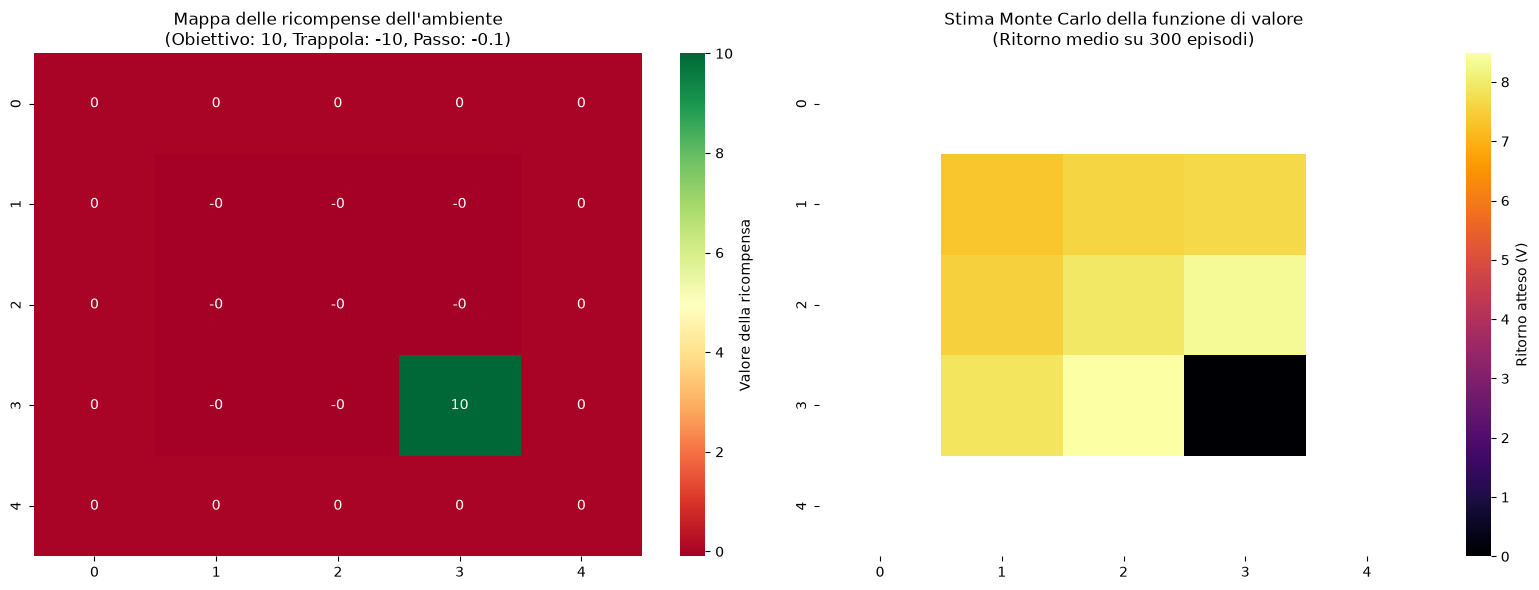

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. A sinistra: la mappa delle ricompense dell'ambiente
sns.heatmap(reward_grid, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax[0], cbar_kws={'label': 'Valore della ricompensa'})
ax[0].set_title("Mappa delle ricompense dell'ambiente\n(Obiettivo: 10, Trappola: -10, Passo: -0.1)")

# 2. A destra: la V stimata con Monte Carlo (First-Visit)
#    Maschero i muri così appaiono vuoti (lì il valore è irrilevante)
mask_walls = (grid_bitmap == 0)
sns.heatmap(V_mc_grid_fv, annot=False, cmap="inferno", ax=ax[1], mask=mask_walls, cbar_kws={'label': 'Ritorno atteso (V)'})

ax[1].set_title("Stima Monte Carlo della funzione di valore\n(Ritorno medio su 300 episodi)")

plt.tight_layout()
plt.show()

## Estrazione della policy

Ora da questa V possiamo estrarre una policy greedy!

Per ogni stato possiamo usare come policy lo spostamento verso lo stato che massimizza la ricompensa.

Poi rifacciamo il passo Monte Carlo e vediamo cosa succede alla funzione di valore.

In [49]:
def extract_greedy(V, grid_bitmap, terminal_mask):
    """Per ogni stato scelgo l'azione che porta nella cella vicina con V più alta."""
    nrows = V.shape[0]
    ncols = V.shape[1]

    # 1. Inizializzo la policy a -1 (nessuna azione) per tutti gli stati
    policy_vals = np.zeros(nrows * ncols, dtype=np.int32) - 1
    for i in range(nrows):
        for j in range(ncols):
            idx = i*ncols + j

            # 2. Salto muri e stati terminali: lì non serve un'azione
            if grid_bitmap[i, j] == 0 or terminal_mask[i, j]:
                continue

            # 3. Leggo il valore dei 4 vicini; se il vicino è un muro o una trappola
            #    gli do -inf così non verrà mai scelto
            up_val = V[i - 1, j] if (grid_bitmap[i - 1, j] != 0 and grid_bitmap[i - 1, j] != 50) else -np.inf

            down_val = V[i + 1, j] if (grid_bitmap[i + 1, j] != 0 and grid_bitmap[i + 1, j] != 50) else -np.inf

            left_val = V[i, j - 1] if (grid_bitmap[i, j - 1] != 0 and grid_bitmap[i, j - 1] != 50) else -np.inf

            right_val = V[i, j + 1] if (grid_bitmap[i, j + 1] != 0 and grid_bitmap[i, j + 1] != 50) else -np.inf

            # 4. Scelgo l'azione con valore massimo (0=SU, 1=GIÙ, 2=SINISTRA, 3=DESTRA)
            policy_vals[idx] = np.argmax([up_val, down_val, left_val, right_val])


    return policy_vals

In [50]:
def plot_policy_from_func(V_grid, grid_bitmap, policy_func, title="Mappa della policy"):
    """Disegno la heatmap di V e sopra una freccia con l'azione scelta dalla policy in ogni stato."""
    nrows, ncols = grid_bitmap.shape
    plt.figure(figsize=(10, 8))

    # 1. Heatmap di sfondo con i valori V (muri mascherati)
    mask_walls = (grid_bitmap == 0)
    sns.heatmap(V_grid, annot=False, cmap='inferno', mask=mask_walls, cbar_kws={'label': 'Valore'}, vmin=-15, vmax=+15)

    # 2. Spostamento (dx, dy) della freccia per ogni azione: 0=SU, 1=GIÙ, 2=SINISTRA, 3=DESTRA
    arrows = {0: (0, -0.3), 1: (0, 0.3), 2: (-0.3, 0), 3: (0.3, 0)}

    for i in range(nrows):
        for j in range(ncols):
            s = i * ncols + j

            # 3. Non disegno frecce su muri, trappole e obiettivo
            if grid_bitmap[i, j] in [0, 50, 200]:
                continue

            # 4. Chiedo alla policy quale azione sceglie in questo stato
            action = policy_func(s)

            # 5. Disegno la freccia partendo dal centro della cella (+0.5)
            dx, dy = arrows[action]
            plt.arrow(j + 0.5, i + 0.5, dx, dy,
                      head_width=0.15, head_length=0.15,
                      fc='white', ec='white', alpha=0.9)

    plt.title(title)
    plt.show()

Episodio terminato dopo 2 passi
Episodio terminato dopo 1 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 4 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 4 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 4 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 1 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 1 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 1 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 3 passi
Episodio terminato dopo 2 passi
Episodio terminato dopo 2 passi
Episodio

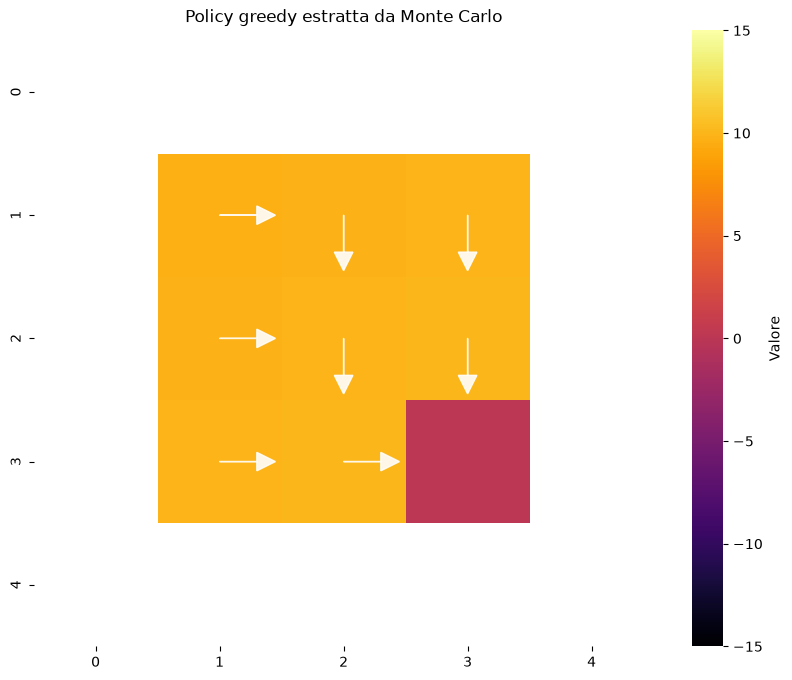

In [51]:
# TODO: uso Monte Carlo per simulare ed estrarre la policy

def extract_greedy_lookahead(V, grid_bitmap, reward_grid, terminal_mask, gamma=1.0):
    """Per ogni stato scelgo l'azione che massimizza r + gamma * V(s'), guardando un passo avanti."""
    nrows, ncols = V.shape
    policy = np.zeros(nrows * ncols, dtype=np.int32) - 1

    for s in range(nrows * ncols):
        i, j = divmod(s, ncols)

        # 1. Salto muri e stati terminali: lì non serve un'azione
        if grid_bitmap[i, j] == 0 or terminal_mask[i, j]:
            continue

        # 2. Per ogni azione calcolo ricompensa immediata + valore dello stato di arrivo
        #    (se lo stato di arrivo è terminale, dopo non c'è più niente: conta solo r)
        q_values = []
        for a_idx in range(4):
            s_next, reward, done = step(s, a_idx, grid_bitmap, reward_grid, terminal_mask)
            q_values.append(reward + gamma * V.flat[s_next] * (not done))

        # 3. Scelgo l'azione migliore
        policy[s] = np.argmax(q_values)

    return policy

# 1. Estraggo la policy greedy dalla V stimata con Monte Carlo (cella 15)
policy_vals_mc = extract_greedy_lookahead(V_mc_grid_fv, grid_bitmap, reward_grid, terminal_mask)

def mc_greedy_policy(s):
    """Restituisco l'azione greedy estratta da Monte Carlo per lo stato s."""
    return policy_vals_mc[s]

# 2. Rifaccio Monte Carlo seguendo la nuova policy greedy
V_mc_greedy = first_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, mc_greedy_policy, num_episodes=300, max_steps=200, random_start=True)

# 3. Disegno la policy sopra la nuova V
plot_policy_from_func(V_mc_greedy, grid_bitmap, mc_greedy_policy, title="Policy greedy estratta da Monte Carlo")

---

Proviamo a estrarla dal sistema lineare risolto

In [52]:
def build_matrices_from_random_policy(grid_bitmap, reward_grid, terminal_mask, gamma=0.9):
    """Costruisco P (N x N) e R (N) per la policy casuale uniforme."""
    rows, cols = grid_bitmap.shape
    num_states = rows * cols

    # Inizializzo P come matrice N x N e R come vettore N x 1
    P = np.zeros((num_states, num_states))
    R_vec = np.zeros(num_states)

    for s in range(num_states):
        r, c = divmod(s, cols)

        # In un MDP, gli stati terminali transitano su sé stessi con prob 1.0
        if terminal_mask[r, c] or grid_bitmap[r, c] == 0: # è un muro o uno stato terminale
            P[s, s] = 1.0
            continue

        # 1. Policy casuale uniforme: pi(a|s) = 1/4 per ogni azione
        prob_per_action = 0.25
        for a_idx in range(4):
            # 2. Uso step per trovare dove porta l'azione e con quale ricompensa
            # dr, dc = [(-1,0), (1,0), (0,-1), (0,1)][a_idx]
            s_next, reward, _ = step(s, a_idx, grid_bitmap, reward_grid, terminal_mask)

            # 3. Aggiorno la matrice di transizione P[from_state, to_state]
            #    (uso += perché azioni diverse possono portare allo stesso stato, es. contro i muri)
            P[s, s_next] += prob_per_action

            # 4. Aggiorno la ricompensa attesa: R(s) = sum_a pi(a|s) * Reward(s, a)
            R_vec[s] += prob_per_action * reward

    return P, R_vec


def solve_bellman_analytical(P, R_vec, gamma=0.9):
    """
    Risolve (I - gamma*P)V = R
    """
    num_states = P.shape[0]
    I = np.eye(num_states)

    # Risolvo il sistema lineare Ax = b
    # dove A = (I - gamma*P) e b = R_vec

    # 1. Costruisco la matrice del sistema
    A = I - gamma * P

    # 2. Risolvo con np.linalg.solve (più stabile e veloce che calcolare l'inversa)
    V_exact = np.linalg.solve(A, R_vec)

    return V_exact

In [53]:
# 1. Costruisco la matrice di transizione P e il vettore delle ricompense attese R
P, R_vec = build_matrices_from_random_policy(grid_bitmap, reward_grid, terminal_mask)

# 2. Risolvo il sistema di Bellman per ottenere la V esatta
V_exact = solve_bellman_analytical(P, R_vec, gamma=0.9)

# 3. Riporto i vettori alla forma della griglia per poterli disegnare
V_exact_grid = V_exact.reshape(rows, cols)

R_expected_grid = R_vec.reshape(rows, cols)

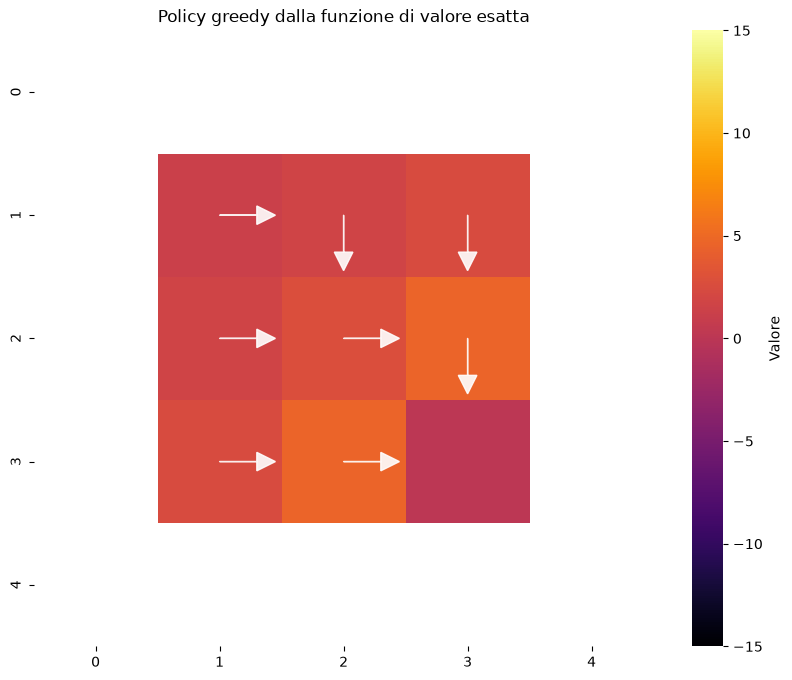

In [54]:
def greedy_policy(s):
    """Restituisco l'azione greedy precalcolata per lo stato s."""
    return policy_vals[s]

# 1. Estraggo la policy greedy dalla V esatta calcolata con Bellman
policy_vals = extract_greedy_lookahead(V_exact_grid, grid_bitmap, reward_grid, terminal_mask, gamma=0.9)

# 2. Disegno le frecce della policy sopra la V esatta
plot_policy_from_func(V_exact_grid, grid_bitmap, greedy_policy, title="Policy greedy dalla funzione di valore esatta")